<a href="https://colab.research.google.com/github/JoaoSoaresv7/Sistema-Especialista-triagem-manchester/blob/main/Aprendizado_Maquina_Triagem_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Aprendizado de Máquina – Introdução
## Sistema especialista com aprendizado supervisionado: triagem clínica
**Aluno:** João Soares · **Disciplina:** Inteligência Artificial e LFA | Sistemas Especialistas · **Profa.** Kadidja Valéria

**Objetivo:** treinar um classificador que estima o **nível de risco** (`baixo`, `medio`, `alto`) de um paciente e usar essa previsão como fato em regras que recomendam a **cor de classificação** e o tempo máximo de espera.

**Leitura:** [Guia IBM](https://www.ibm.com/br-pt/think/machine-learning) e [aprendizado supervisionado](https://www.ibm.com/br-pt/think/topics/supervised-learning).

**Aviso:** os dados são **simulados** e muito pequenos. Este exemplo não valida uma ferramenta clínica, não diagnostica e não substitui o profissional de saúde.

## 0. Estudo inicial (leitura do guia da IBM)

**O que é aprendizado de máquina?** É a parte da IA em que o algoritmo aprende padrões a partir de dados de treino e depois usa esses padrões para prever casos novos, sem que alguém escreva todas as regras à mão.

**O que é aprendizado supervisionado?** Os exemplos de treino já vêm com a resposta certa, o rótulo (verdade fundamental). O modelo compara o que previu com o rótulo e ajusta seus parâmetros. Aqui o rótulo é o risco de cada paciente simulado.

**O que são atributos e rótulos?** Atributos são as entradas: escala de dor, saturação de O2 e temperatura. O rótulo é a resposta conhecida: `baixo`, `medio` ou `alto`.

**Como classificação difere de regressão?** A classificação prevê uma categoria (o nível de risco); a regressão prevê um número contínuo (por exemplo, o tempo de espera em minutos). Este problema é de classificação.

**Por que separar treino e teste?** Para medir o modelo com casos que ele nunca viu. Avaliar com os mesmos dados do treino seria como fazer a prova com as questões da lista: dá para acertar sem ter aprendido, e o sobreajuste (overfitting) passaria despercebido.

## 1. Preparar o ambiente
No Colab, as bibliotecas geralmente já estão disponíveis. Se o próximo bloco apresentar `ModuleNotFoundError`, execute em uma nova célula: `%pip install pandas scikit-learn matplotlib` e tente novamente.

In [ ]:
# pandas: manipulação de dados estruturados
import pandas as pd
# matplotlib.pyplot: gráficos
import matplotlib.pyplot as plt
# train_test_split: divisão em treino e teste
from sklearn.model_selection import train_test_split
# DecisionTreeClassifier: árvore de decisão; export_text e plot_tree mostram as condições aprendidas
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree
# Métricas: acurácia e matriz de confusão
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

print("Bibliotecas carregadas.")

Bibliotecas carregadas.


## 2. Dataset rotulado
Cada linha é um paciente **simulado**. As entradas são a escala de dor (0 a 10), a saturação de oxigênio (%) e a temperatura (°C). O rótulo `risco` é a resposta conhecida.

**Origem e tamanho:** 24 casos inventados para esta demonstração (8 por classe). Nenhum vem de paciente real.

**Critério de rotulagem (atribuído manualmente, sem profissional de saúde):**
- `alto`: dor ≥ 8, **ou** saturação < 92%, **ou** temperatura ≥ 39,5 °C.
- `medio`: dor de 5 a 7, **ou** saturação de 92 a 94%, **ou** temperatura de 37,8 a 39,4 °C.
- `baixo`: nenhum dos critérios acima.

Em um projeto real, os rótulos viriam de profissionais, com critérios e evidências documentados. Os limiares aqui são didáticos, inspirados no Protocolo de Manchester e no Caderno de Atenção Básica nº 28 (Ministério da Saúde), e **não foram validados clinicamente**.

In [ ]:
# Atributos: dor_escala, saturacao_o2, febre_temp | Rótulo: risco (baixo, medio ou alto)
dados = pd.DataFrame({
    "dor_escala":   [1, 2, 0, 3, 2, 3, 1, 4,   5, 6, 7, 5, 6, 4, 7, 5,   8, 9, 10, 6, 5, 7, 4, 9],
    "saturacao_o2": [98, 97, 99, 98, 96, 97, 99, 97,   96, 95, 97, 93, 94, 93, 95, 94,   96, 95, 97, 90, 88, 91, 89, 92],
    "febre_temp":   [36.5, 36.8, 36.6, 37.0, 37.2, 36.9, 37.4, 37.5,   37.8, 38.2, 38.6, 37.5, 38.0, 38.5, 39.0, 38.8,   37.0, 38.0, 39.0, 38.0, 37.5, 39.6, 40.0, 40.2],
    "risco":        ["baixo"] * 8 + ["medio"] * 8 + ["alto"] * 8,
})

# Confere se os rótulos seguem o critério descrito acima
def criterio(l):
    if l.dor_escala >= 8 or l.saturacao_o2 < 92 or l.febre_temp >= 39.5: return "alto"
    if 5 <= l.dor_escala <= 7 or 92 <= l.saturacao_o2 <= 94 or l.febre_temp >= 37.8: return "medio"
    return "baixo"
assert (dados.apply(criterio, axis=1) == dados["risco"]).all(), "rótulo diferente do critério"

print(dados.to_string(index=False))
print("\nQuantidade por classe:")
print(dados["risco"].value_counts())

 dor_escala  saturacao_o2  febre_temp risco
          1            98        36.5 baixo
          2            97        36.8 baixo
          0            99        36.6 baixo
          3            98        37.0 baixo
          2            96        37.2 baixo
          3            97        36.9 baixo
          1            99        37.4 baixo
          4            97        37.5 baixo
          5            96        37.8 medio
          6            95        38.2 medio
          7            97        38.6 medio
          5            93        37.5 medio
          6            94        38.0 medio
          4            93        38.5 medio
          7            95        39.0 medio
          5            94        38.8 medio
          8            96        37.0  alto
          9            95        38.0  alto
         10            97        39.0  alto
          6            90        38.0  alto
          5            88        37.5  alto
          7            91       

## 3. Separar treinamento e teste
`X` contém os atributos e `y` contém o rótulo. Reservamos 25% dos exemplos para teste: são 18 de treino e 6 de teste. `stratify` preserva a proporção das classes; `random_state` torna a divisão reproduzível. O rótulo nunca entra em `X`.

In [ ]:
X = dados[["dor_escala", "saturacao_o2", "febre_temp"]]
y = dados["risco"]

# 75% treino, 25% teste; stratify mantém a proporção das classes; random_state=42 reproduz o resultado
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)
print("Treino:", len(X_treino), "| Teste:", len(X_teste))

Treino: 18 | Teste: 6


## 4. Treinar e avaliar
`fit` aprende padrões somente no treino; `predict` gera previsões. Acurácia é a fração de acertos no teste. Na matriz, linhas são classes reais e colunas são previstas. Não ajuste o modelo repetidamente para acertar este mesmo teste: use validação separada se fizer ajustes.

Acurácia no teste: 83.3%
       baixo  medio  alto
baixo      2      0     0
medio      0      2     0
alto       0      1     1


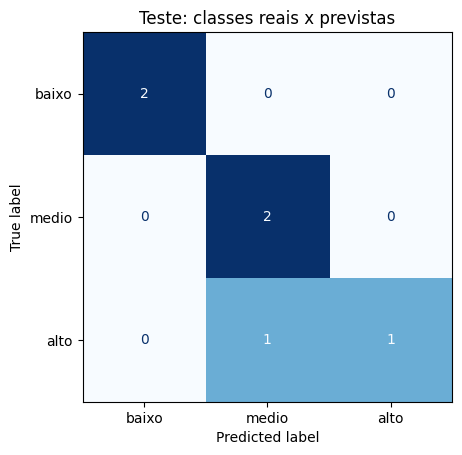

Condições aprendidas:
|--- dor_escala <= 4.50
|   |--- febre_temp <= 38.00
|   |   |--- class: baixo
|   |--- febre_temp >  38.00
|   |   |--- class: medio
|--- dor_escala >  4.50
|   |--- dor_escala <= 7.50
|   |   |--- saturacao_o2 <= 92.00
|   |   |   |--- class: alto
|   |   |--- saturacao_o2 >  92.00
|   |   |   |--- class: medio
|   |--- dor_escala >  7.50
|   |   |--- class: alto



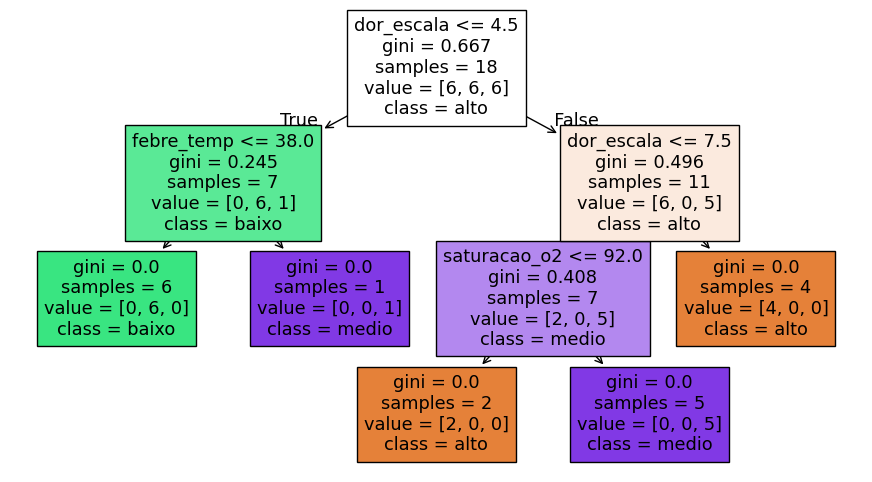

In [ ]:
# Árvore de decisão com profundidade limitada a 3 (poucos dados: profundidade maior só decoraria o treino)
modelo = DecisionTreeClassifier(max_depth=3, random_state=42)
modelo.fit(X_treino, y_treino)
previsoes = modelo.predict(X_teste)

print(f"Acurácia no teste: {accuracy_score(y_teste, previsoes):.1%}")

classes = ["baixo", "medio", "alto"]
matriz = confusion_matrix(y_teste, previsoes, labels=classes)
print(pd.DataFrame(matriz, index=classes, columns=classes))

ConfusionMatrixDisplay(matriz, display_labels=classes).plot(cmap="Blues", colorbar=False)
plt.title("Teste: classes reais x previstas")
plt.show()

print("Condições aprendidas:")
print(export_text(modelo, feature_names=list(X.columns)))

plt.figure(figsize=(11, 6))
plot_tree(modelo, feature_names=list(X.columns), class_names=list(modelo.classes_), filled=True)
plt.show()

### Entendendo os termos da árvore de decisão
Cada nó (caixa) mostra três informações:
1. **gini:** mede a impureza (mistura de classes) do nó. `0.0` significa que todos os exemplos ali são da mesma classe; valores maiores indicam mistura.
2. **samples:** quantos exemplos do treino chegaram àquele nó. A raiz começa com os 18 exemplos de treino.
3. **value:** quantos exemplos de cada classe há no nó, na ordem alfabética das classes: `[alto, baixo, medio]`.

**Interpretação:** os dados são simulados e foram rotulados por critérios simples, então a árvore tende a reencontrar esses limiares. Com apenas 6 casos de teste, mesmo 100% de acurácia não demonstra eficácia em pacientes reais. A árvore mostra condições aprendidas; as regras de classificação abaixo foram escritas por pessoas.

## 5. Base de conhecimento e motor de inferência
A previsão vira um fato (`risco`). Outro fato, informado pelo profissional, é se há **sinais de alarme** (vias aéreas comprometidas, sinais de choque ou convulsão ativa). O motor ordena as regras por **saliência** (prioridade), dispara a primeira que casa com os fatos e devolve a cor, o tempo máximo de espera e a justificativa.

**Origem das regras:** Protocolo de Manchester (visão geral) e Caderno de Atenção Básica nº 28 do Ministério da Saúde, em versão simplificada e não validada por profissional de saúde.

In [ ]:
# Base de conhecimento: None significa "qualquer valor". Saliência maior dispara primeiro.
regras = [
    {"id": "R1", "salience": 100, "alarme": True,  "risco": None,    "cor": "Vermelho", "tempo": 0,
     "acao": "Atendimento imediato.", "origem": "sinais de alarme exigem atendimento imediato"},
    {"id": "R2", "salience": 80,  "alarme": False, "risco": "alto",  "cor": "Laranja",  "tempo": 10,
     "acao": "Muito urgente: atender em até 10 min.", "origem": "risco alto estimado pelo modelo"},
    {"id": "R3", "salience": 60,  "alarme": False, "risco": "medio", "cor": "Amarelo",  "tempo": 60,
     "acao": "Urgente: atender em até 60 min.", "origem": "risco médio estimado pelo modelo"},
    {"id": "R4", "salience": 40,  "alarme": False, "risco": "baixo", "cor": "Verde",    "tempo": 120,
     "acao": "Pouco urgente: atender em até 120 min.", "origem": "risco baixo estimado pelo modelo"},
]

# Motor de inferência: percorre as regras da maior para a menor saliência e dispara a primeira compatível
def aplicar_regras(risco, alarme):
    for regra in sorted(regras, key=lambda r: -r["salience"]):
        if regra["alarme"] == alarme and regra["risco"] in (None, risco):
            return {
                "risco_previsto": risco,
                "regra": regra["id"],
                "classificacao": f'{regra["cor"]} ({regra["tempo"]} min)',
                "recomendacao": regra["acao"],
                "explicacao": f'Alarme: {alarme}; risco previsto: {risco}; {regra["origem"]}.',
            }
    raise ValueError("Nenhuma regra compatível com os fatos.")

## 6. Integrar o modelo ao sistema especialista
A função valida os valores, faz a previsão e aplica as regras. Valores fora dos intervalos observados no treino recebem um aviso, pois a previsão pode ser menos confiável. O sistema não guarda estado nem dados pessoais: os fatos são descartados ao final.

In [ ]:
def triar(dor, saturacao, temperatura, alarme):
    # Validação dos limites físicos/lógicos das entradas
    if not 0 <= dor <= 10:
        raise ValueError("Escala de dor deve estar entre 0 e 10.")
    if not 50 <= saturacao <= 100:
        raise ValueError("Saturação deve estar entre 50 e 100.")
    if not 30 <= temperatura <= 45:
        raise ValueError("Temperatura deve estar entre 30 e 45 °C.")
    if not isinstance(alarme, bool):
        raise ValueError("Sinais de alarme devem ser True ou False.")

    novo_caso = pd.DataFrame([{"dor_escala": dor, "saturacao_o2": saturacao, "febre_temp": temperatura}])

    # 1. Classificação: o modelo estima o risco
    risco = modelo.predict(novo_caso)[0]
    # 2. Inferência: as regras usam a previsão como fato
    resultado = aplicar_regras(risco, alarme)

    fora = any(not X_treino[c].min() <= novo_caso[c].iloc[0] <= X_treino[c].max() for c in X.columns)
    resultado["aviso"] = (
        "Entrada fora dos intervalos observados no treino."
        if fora else "Protótipo didático; classificação sujeita a revisão do profissional de saúde."
    )
    return resultado

# Três casos novos (não vistos no treinamento): (dor, saturação, temperatura, alarme)
casos = [(2, 97, 36.7, False), (6, 94, 38.4, False), (9, 90, 38.0, False)]

for i, (dor, sat, temp, alarme) in enumerate(casos, 1):
    print(f"\nCASO {i}: dor {dor}; SpO2 {sat}%; {temp} °C; alarme={alarme}")
    for campo, valor in triar(dor, sat, temp, alarme).items():
        print(f"{campo}: {valor}")


CASO 1: dor 2; SpO2 97%; 36.7 °C; alarme=False
risco_previsto: baixo
regra: R4
classificacao: Verde (120 min)
recomendacao: Pouco urgente: atender em até 120 min.
explicacao: Alarme: False; risco previsto: baixo; risco baixo estimado pelo modelo.
aviso: Protótipo didático; classificação sujeita a revisão do profissional de saúde.

CASO 2: dor 6; SpO2 94%; 38.4 °C; alarme=False
risco_previsto: medio
regra: R3
classificacao: Amarelo (60 min)
recomendacao: Urgente: atender em até 60 min.
explicacao: Alarme: False; risco previsto: medio; risco médio estimado pelo modelo.
aviso: Protótipo didático; classificação sujeita a revisão do profissional de saúde.

CASO 3: dor 9; SpO2 90%; 38.0 °C; alarme=False
risco_previsto: alto
regra: R2
classificacao: Laranja (10 min)
recomendacao: Muito urgente: atender em até 10 min.
explicacao: Alarme: False; risco previsto: alto; risco alto estimado pelo modelo.
aviso: Protótipo didático; classificação sujeita a revisão do profissional de saúde.


## 7. Experimente uma consulta
Altere os valores abaixo e execute novamente. Compare dois casos com a **mesma previsão** do modelo e valores diferentes de `alarme`. Qual componente modifica a classificação final?

In [ ]:
dor = 6
saturacao = 94
temperatura = 38.4
alarme = False   # troque para True e compare

resultado = triar(dor, saturacao, temperatura, alarme)
for campo, valor in resultado.items():
    print(f"{campo}: {valor}")

risco_previsto: medio
regra: R3
classificacao: Amarelo (60 min)
recomendacao: Urgente: atender em até 60 min.
explicacao: Alarme: False; risco previsto: medio; risco médio estimado pelo modelo.
aviso: Protótipo didático; classificação sujeita a revisão do profissional de saúde.


## 8. Análise
1. **Problema:** triagem clínica de risco. Entradas: dor, saturação de O2, temperatura e sinais de alarme. Rótulo: risco (`baixo`, `medio`, `alto`). Recomendação: cor de classificação com tempo máximo de espera.
2. **Regras:** quatro regras (R1 a R4), com origem no Protocolo de Manchester (visão geral) e no Caderno de Atenção Básica nº 28, em versão simplificada. No repositório há a versão completa, com 28 regras.
3. **Dataset:** 24 casos simulados, criados para a demonstração e rotulados manualmente por critérios descritos na seção 2. O repositório usa 600 casos simulados gerados por script.
4. **Treino e teste:** seção 4 (acurácia e matriz de confusão).
5. **Previsão usada em regra:** o fato `risco` alimenta R2, R3 e R4 (seção 5).
6. **Três casos novos:** seção 6, com previsão, regra aplicada e explicação.
7. **Erros, limitações e cuidados:** abaixo.

### Erros e limitações
- Com 24 casos, a árvore pode errar fora dos exemplos vistos, e 6 casos de teste são poucos para qualquer conclusão. No teste, a acurácia foi de 83,3% (5 de 6): um caso de risco `alto` foi previsto como `medio`, exatamente o erro mais perigoso, porque subestima a gravidade. A acurácia mostra que o código funciona, não que o sistema serve para pacientes reais.
- Os rótulos seguem critérios que nós definimos, então o modelo aprende a nossa suposição (avaliação circular). Em dados reais, os rótulos seriam de profissionais e variariam entre eles.
- Casos pouco representados: crianças, idosos, gestantes e quadros atípicos não estão nos dados e estão fora do escopo.
- Um erro de risco subestimado é mais grave que um superestimado. Por isso, no sistema completo do repositório o modelo só **escalona** a prioridade e nunca rebaixa nem decide Vermelho, e a decisão final é sempre do profissional.
- Dados pessoais: informação de saúde é dado pessoal sensível (LGPD, Lei 13.709/2018). O sistema não coleta nome, CPF, nascimento nem prontuário e descarta os fatos ao final.

## Referências
- IBM. Guia de Aprendizado de Máquina: https://www.ibm.com/br-pt/think/machine-learning
- IBM. Aprendizado supervisionado: https://www.ibm.com/br-pt/think/topics/supervised-learning
- scikit-learn. DecisionTreeClassifier: https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html
- scikit-learn. train_test_split: https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html
- BRASIL. Ministério da Saúde. Acolhimento à demanda espontânea. Cadernos de Atenção Básica, n. 28, v. I. Brasília, 2011.
- BRASIL. Lei nº 13.709/2018 (LGPD): https://www.planalto.gov.br/ccivil_03/_ato2015-2018/2018/lei/l13709.htm